<a href="https://colab.research.google.com/github/Nurdaulet247/Python-Pandas/blob/main/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D0%BA%D0%B0%D0%BB%D1%8B%D2%9B_%D0%B6%D2%B1%D0%BC%D1%8B%D1%81_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Кітапханалар сәтті жүктелді")


Кітапханалар сәтті жүктелді


In [ ]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/banknote_authentication.csv"

try:
    df = pd.read_csv(url, header=None)
except Exception:
    url = "https://raw.githubusercontent.com/selva86/datasets/master/banknote.csv"
    df = pd.read_csv(url, header=None)

df.rename(columns={0: 'variance', 1: 'skewness', 2: 'curtosis', 3: 'entropy', 4: 'class'}, inplace=True)

print("Деректер көлемі:", df.shape)
display(df.head())

Деректер көлемі: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [ ]:
print("=== ДЕРЕКТЕР ТУРАЛЫ АҚПАРАТ ===")
df.info()

print("\n=== СИПАТТАМАЛЫҚ СТАТИСТИКА ===")
display(df.describe())

print("\n=== БОС МӘНДЕР ===")
missing = df.isnull().sum()
display(missing.to_frame("Бос мәндер саны"))

print("\n=== КЛАСТАРДЫҢ САНЫ ===")
display(df["class"].value_counts().sort_index())


=== ДЕРЕКТЕР ТУРАЛЫ АҚПАРАТ ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1371 entries, 0 to 1370
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   3.6216    1371 non-null   float64
 1   8.6661    1371 non-null   float64
 2   -2.8073   1371 non-null   float64
 3   -0.44699  1371 non-null   float64
 4   class     1371 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

=== СИПАТТАМАЛЫҚ СТАТИСТИКА ===


,3.6216,8.6661,-2.8073,-0.44699,class
count,1371.000000,1371.000000,1371.000000,1371.000000,1371.000000
mean,0.431410,1.917434,1.400694,-1.192200,0.444931
std,2.842494,5.868359,4.310105,2.101683,0.497139
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.774700,-1.711300,-1.553350,-2.417000,0.000000
50%,0.495710,2.313400,0.616630,-0.586650,0.000000
75%,2.814650,6.813100,3.181600,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000



=== БОС МӘНДЕР ===


,Бос мәндер саны
3.6216,0
8.6661,0
-2.8073,0
-0.44699,0
class,0



=== КЛАСТАРДЫҢ САНЫ ===


,count
class,
0,761
1,610


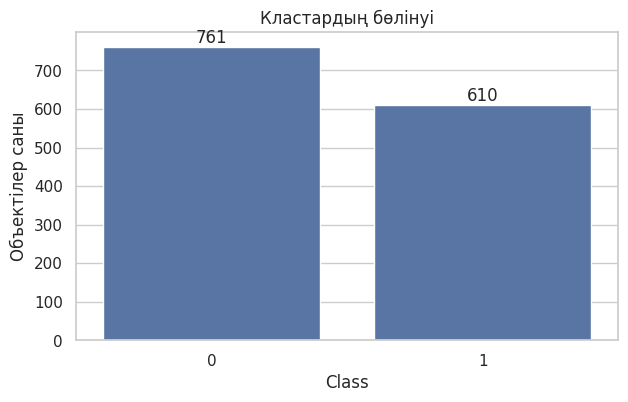

Объектілер саны: 1371
Белгілер саны: 4
Бос мәндердің жалпы саны: 0
Класс саны: 2


In [ ]:
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x="class")
plt.title("Кластардың бөлінуі")
plt.xlabel("Class")
plt.ylabel("Объектілер саны")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

print(f"Объектілер саны: {len(df)}")
print(f"Белгілер саны: {df.drop(columns='class').shape[1]}")
print(f"Бос мәндердің жалпы саны: {df.isnull().sum().sum()}")
print(f"Класс саны: {df['class'].nunique()}")


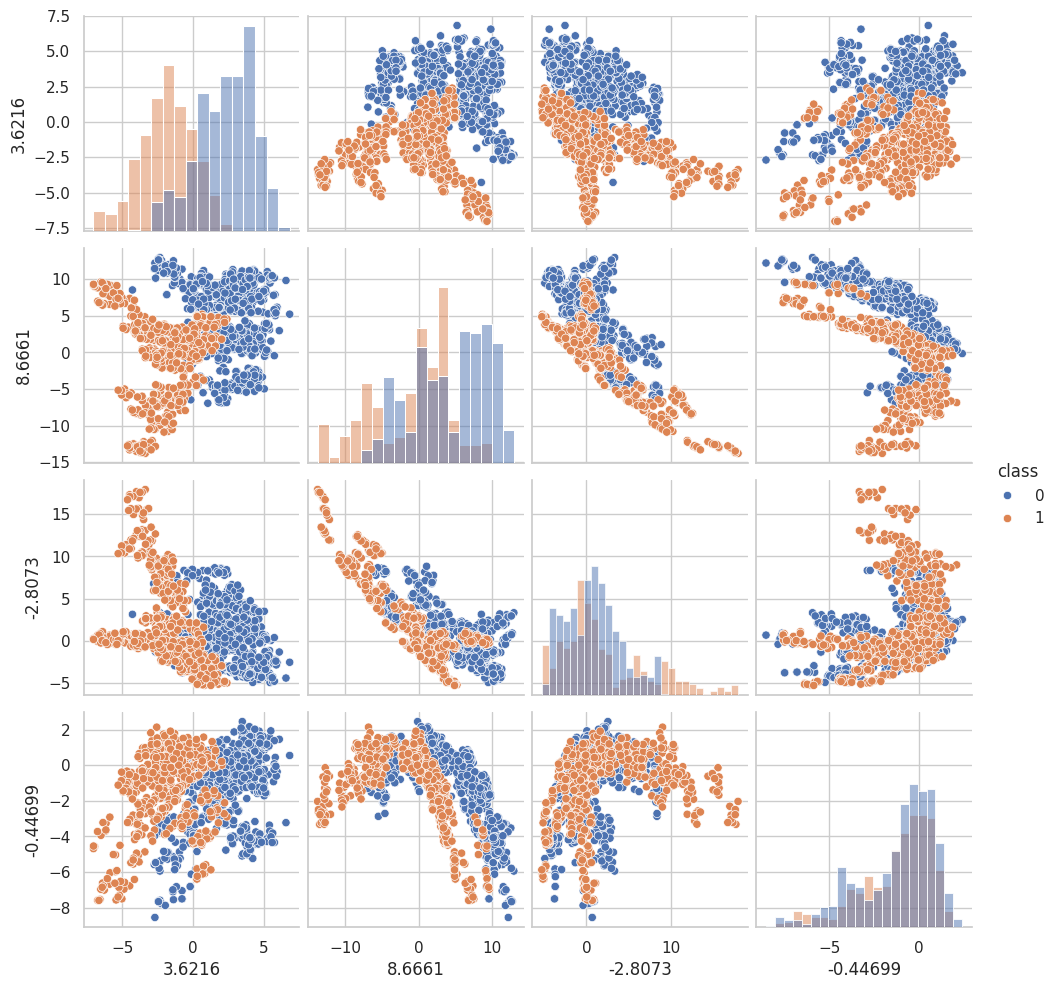

In [ ]:
sns.pairplot(df, hue="class", diag_kind="hist")
plt.show()


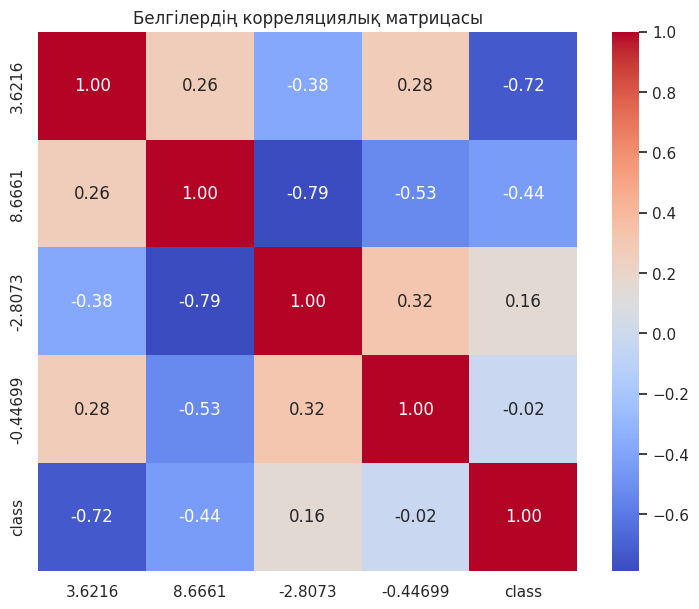

Ең күшті корреляциялар:


Корреляция
8.6661 -2.8073    -0.786729
3.6216 class      -0.724655
8.6661 -0.44699   -0.526896
       class      -0.444281
3.6216 -2.8073    -0.380358

In [ ]:
plt.figure(figsize=(9, 7))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Белгілердің корреляциялық матрицасы")
plt.show()

corr_pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        .stack()
        .sort_values(key=np.abs, ascending=False)
)

print("Ең күшті корреляциялар:")
display(corr_pairs.head(5).to_frame("Корреляция"))


In [ ]:
X = df.drop("class", axis=1)
y = df["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train.shape)
print("Test :", X_test.shape)


Train: (1097, 4)
Test : (275, 4)


=== LOGISTIC REGRESSION ===
Accuracy  : 0.9818
Precision : 0.9606
Recall    : 1.0000
F1-score  : 0.9799

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98       153
           1       0.96      1.00      0.98       122

    accuracy                           0.98       275
   macro avg       0.98      0.98      0.98       275
weighted avg       0.98      0.98      0.98       275



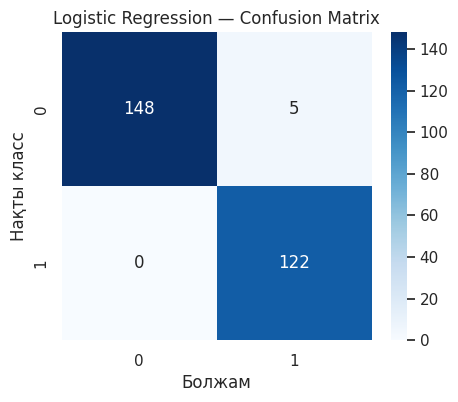

In [ ]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

lr_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_lr),
    "Precision": precision_score(y_test, y_pred_lr),
    "Recall": recall_score(y_test, y_pred_lr),
    "F1-score": f1_score(y_test, y_pred_lr)
}

print("=== LOGISTIC REGRESSION ===")
for name, value in lr_metrics.items():
    print(f"{name:10s}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_test, y_pred_lr),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=["0", "1"], yticklabels=["0", "1"]
)
plt.title("Logistic Regression — Confusion Matrix")
plt.xlabel("Болжам")
plt.ylabel("Нақты класс")
plt.show()


,k,Accuracy,Precision,Recall,F1-score
0,1,1.0000,1.0000,1.0000,1.0000
1,3,1.0000,1.0000,1.0000,1.0000
2,5,1.0000,1.0000,1.0000,1.0000
3,7,1.0000,1.0000,1.0000,1.0000
4,9,1.0000,1.0000,1.0000,1.0000
5,11,1.0000,1.0000,1.0000,1.0000
6,15,1.0000,1.0000,1.0000,1.0000


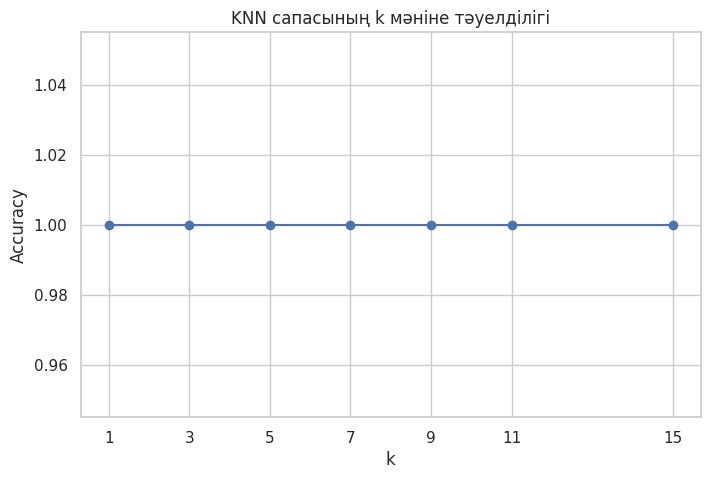

Ең жоғары Accuracy көрсеткен k = 1
Accuracy = 1.0000


In [ ]:
k_values = [1, 3, 5, 7, 9, 11, 15]
knn_results = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)

    knn_results.append({
        "k": k,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred)
    })

knn_df = pd.DataFrame(knn_results)
display(knn_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1-score": "{:.4f}"
}))

plt.figure(figsize=(8, 5))
plt.plot(knn_df["k"], knn_df["Accuracy"], marker="o")
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("KNN сапасының k мәніне тәуелділігі")
plt.xticks(k_values)
plt.grid(True)
plt.show()

best_knn = knn_df.loc[knn_df["Accuracy"].idxmax()]
print(f"Ең жоғары Accuracy көрсеткен k = {int(best_knn['k'])}")
print(f"Accuracy = {best_knn['Accuracy']:.4f}")


,max_depth,Accuracy,Precision,Recall,F1-score
0,2,0.9236,0.9316,0.8934,0.9121
1,4,0.9673,0.9520,0.9754,0.9636
2,6,0.9782,0.9754,0.9754,0.9754


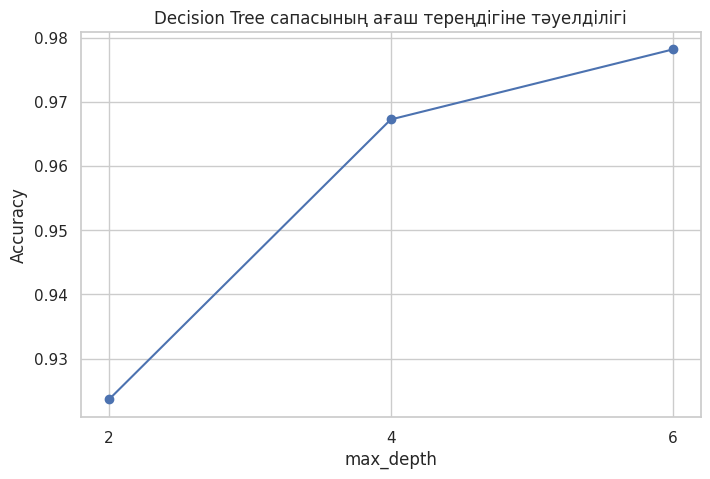

In [ ]:
depth_values = [2, 4, 6]
tree_results = []
trees = {}

for depth in depth_values:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)
    y_pred = tree.predict(X_test)

    trees[depth] = tree
    tree_results.append({
        "max_depth": depth,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred)
    })

tree_df = pd.DataFrame(tree_results)
display(tree_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1-score": "{:.4f}"
}))

plt.figure(figsize=(8, 5))
plt.plot(tree_df["max_depth"], tree_df["Accuracy"], marker="o")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree сапасының ағаш тереңдігіне тәуелділігі")
plt.xticks(depth_values)
plt.grid(True)
plt.show()


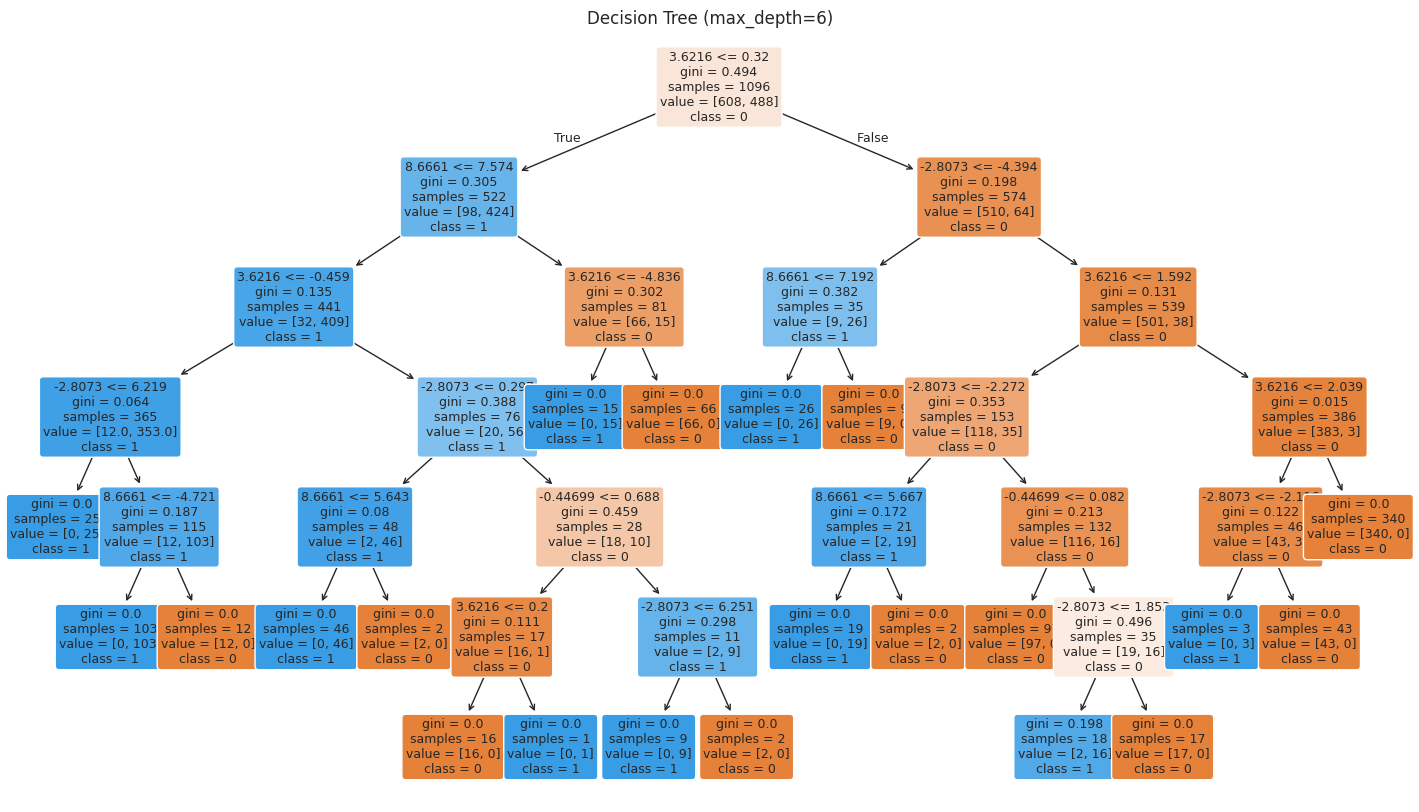

Ағаштың бастапқы түйінінде қолданылған белгі: 3.6216


In [ ]:
plt.figure(figsize=(18, 10))
plot_tree(
    trees[6],
    feature_names=X.columns,
    class_names=["0", "1"],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree (max_depth=6)")
plt.show()

root_feature = X.columns[trees[6].tree_.feature[0]]
print("Ағаштың бастапқы түйінінде қолданылған белгі:", root_feature)


In [ ]:
feature_sets = {
    "Барлық 4 белгі": ["variance", "skewness", "curtosis", "entropy"],
    "variance + skewness": ["variance", "skewness"],
    "curtosis + entropy": ["curtosis", "entropy"]
}

feature_results = []

for set_name, features in feature_sets.items():
    # Re-extract X_sub and y from the global df to ensure consistency
    X_sub = df[features]
    y_sub = df["class"]

    Xtr, Xte, ytr, yte = train_test_split(
        X_sub, y_sub, test_size=0.2, random_state=42, stratify=y_sub
    )

    scaler_sub = StandardScaler()
    Xtr_s = scaler_sub.fit_transform(Xtr)
    Xte_s = scaler_sub.transform(Xte)

    models = {
        "Logistic Regression": LogisticRegression(max_iter=1000),
        "KNN": KNeighborsClassifier(n_neighbors=5),
        "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=42)
    }

    for model_name, model in models.items():
        if model_name == "Decision Tree":
            model.fit(Xtr, ytr)
            pred = model.predict(Xte)
        else:
            model.fit(Xtr_s, ytr)
            pred = model.predict(Xte_s)

        feature_results.append({
            "Белгілер жиынтығы": set_name,
            "Модель": model_name,
            "Accuracy": accuracy_score(yte, pred)
        })

feature_df = pd.DataFrame(feature_results)
display(
    feature_df.pivot(
        index="Белгілер жиынтығы",
        columns="Модель",
        values="Accuracy"
    ).style.format("{:.4f}")
)


Модель,Decision Tree,KNN,Logistic Regression
Белгілер жиынтығы,,,
curtosis + entropy,0.6800,0.7200,0.6145
variance + skewness,0.9309,0.9273,0.8800
Барлық 4 белгі,0.9927,1.0000,0.9709


,Модель,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.9818,0.9606,1.0000,0.9799
1,KNN (k=1),1.0000,1.0000,1.0000,1.0000
2,Decision Tree (depth=6),0.9782,0.9754,0.9754,0.9754


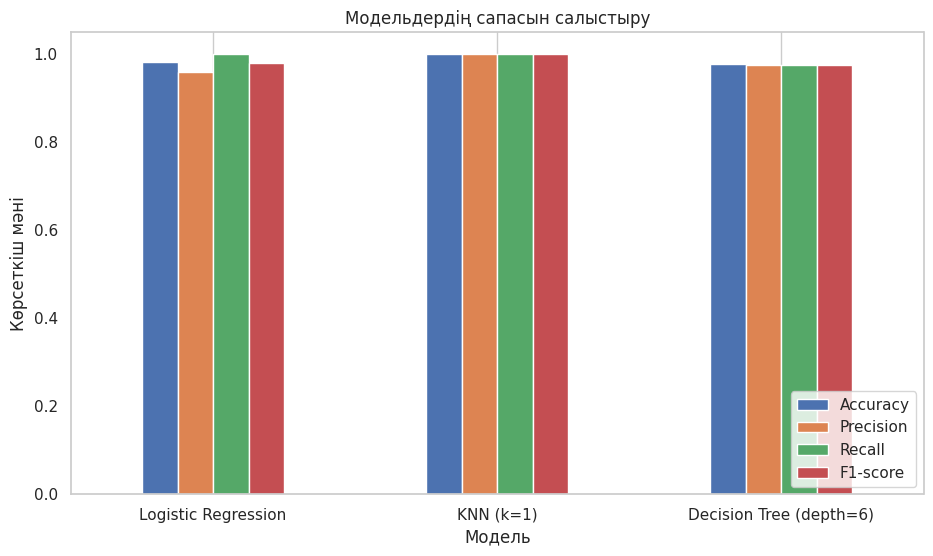

In [ ]:
best_k = int(knn_df.loc[knn_df["Accuracy"].idxmax(), "k"])
best_depth = int(tree_df.loc[tree_df["Accuracy"].idxmax(), "max_depth"])

knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train_scaled, y_train)
pred_knn = knn_best.predict(X_test_scaled)

tree_best = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
tree_best.fit(X_train, y_train)
pred_tree = tree_best.predict(X_test)

summary = pd.DataFrame([
    {
        "Модель": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_lr),
        "Precision": precision_score(y_test, y_pred_lr),
        "Recall": recall_score(y_test, y_pred_lr),
        "F1-score": f1_score(y_test, y_pred_lr)
    },
    {
        "Модель": f"KNN (k={best_k})",
        "Accuracy": accuracy_score(y_test, pred_knn),
        "Precision": precision_score(y_test, pred_knn),
        "Recall": recall_score(y_test, pred_knn),
        "F1-score": f1_score(y_test, pred_knn)
    },
    {
        "Модель": f"Decision Tree (depth={best_depth})",
        "Accuracy": accuracy_score(y_test, pred_tree),
        "Precision": precision_score(y_test, pred_tree),
        "Recall": recall_score(y_test, pred_tree),
        "F1-score": f1_score(y_test, pred_tree)
    }
])

display(summary.style.format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1-score": "{:.4f}"
}))

summary.set_index("Модель").plot(kind="bar", figsize=(11, 6))
plt.title("Модельдердің сапасын салыстыру")
plt.ylabel("Көрсеткіш мәні")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.show()


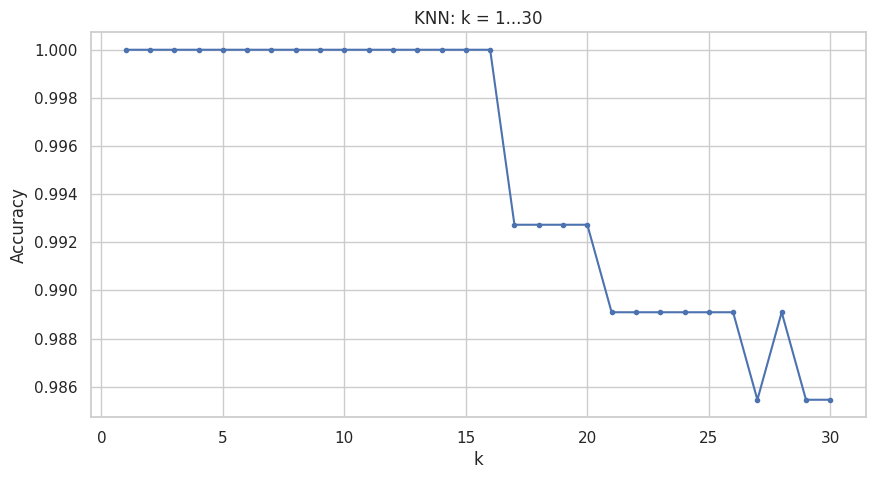

Ең жақсы k: 1
Ең жоғары Accuracy: 1.0


In [ ]:
knn_30 = []

for k in range(1, 31):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    knn_30.append(accuracy_score(y_test, pred))

plt.figure(figsize=(10, 5))
plt.plot(range(1, 31), knn_30, marker=".")
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("KNN: k = 1...30")
plt.grid(True)
plt.show()

print("Ең жақсы k:", np.argmax(knn_30) + 1)
print("Ең жоғары Accuracy:", max(knn_30))


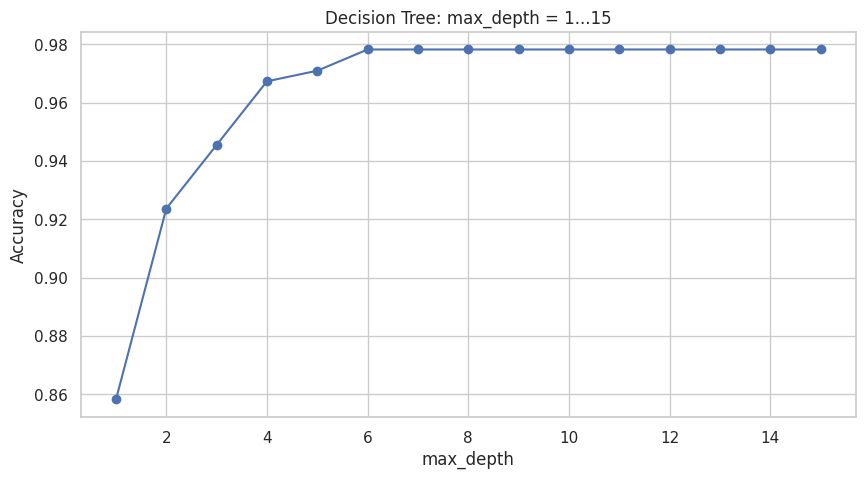

Ең жақсы max_depth: 6
Ең жоғары Accuracy: 0.9781818181818182


In [ ]:
depth_15 = []

for depth in range(1, 16):
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    depth_15.append(accuracy_score(y_test, pred))

plt.figure(figsize=(10, 5))
plt.plot(range(1, 16), depth_15, marker="o")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: max_depth = 1...15")
plt.grid(True)
plt.show()

print("Ең жақсы max_depth:", np.argmax(depth_15) + 1)
print("Ең жоғары Accuracy:", max(depth_15))


,C,Accuracy
0,0.010000,0.9491
1,0.100000,0.9782
2,1.000000,0.9818
3,10.000000,0.9927
4,100.000000,0.9927


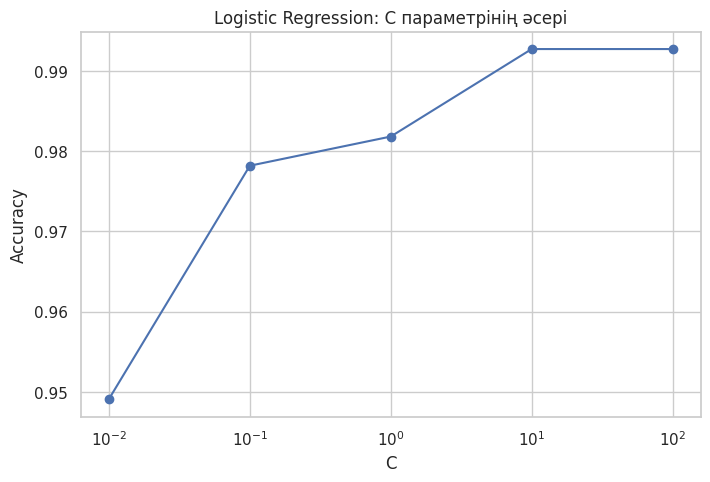

In [ ]:
C_values = [0.01, 0.1, 1, 10, 100]
C_results = []

for C in C_values:
    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    C_results.append(accuracy_score(y_test, pred))

C_df = pd.DataFrame({"C": C_values, "Accuracy": C_results})
display(C_df.style.format({"Accuracy": "{:.4f}"}))

plt.figure(figsize=(8, 5))
plt.semilogx(C_values, C_results, marker="o")
plt.xlabel("C")
plt.ylabel("Accuracy")
plt.title("Logistic Regression: C параметрінің әсері")
plt.grid(True)
plt.show()


In [ ]:
leave_one_out = []

for removed in X.columns:
    features = [c for c in X.columns if c != removed]
    X_sub = df[features]

    Xtr, Xte, ytr, yte = train_test_split(
        X_sub, y, test_size=0.2, random_state=42, stratify=y
    )

    scaler_tmp = StandardScaler()
    Xtr_s = scaler_tmp.fit_transform(Xtr)
    Xte_s = scaler_tmp.transform(Xte)

    model = LogisticRegression(max_iter=1000)
    model.fit(Xtr_s, ytr)
    pred = model.predict(Xte_s)

    leave_one_out.append({
        "Алынып тасталған белгі": removed,
        "Қалған белгілер": ", ".join(features),
        "Accuracy": accuracy_score(yte, pred)
    })

loo_df = pd.DataFrame(leave_one_out)
display(loo_df.style.format({"Accuracy": "{:.4f}"}))


,Алынып тасталған белгі,Қалған белгілер,Accuracy
0,variance,"skewness, curtosis, entropy",0.7891
1,skewness,"variance, curtosis, entropy",0.9055
2,curtosis,"variance, skewness, entropy",0.8800
3,entropy,"variance, skewness, curtosis",0.9709


In [ ]:
best_summary_model = summary.loc[summary["Accuracy"].idxmax(), "Модель"]
best_summary_acc = summary["Accuracy"].max()

best_k_idx = int(np.argmax(knn_30)) + 1
best_depth_idx = int(np.argmax(depth_15)) + 1
best_c_idx = int(np.argmax(C_results))
best_c = C_values[best_c_idx]

print("=== ҚОРЫТЫНДЫ ===")
print(
    f"1. Бұл жұмыста Banknote Authentication деректер жиынтығы негізінде бинарлық классификация орындалды."
)
print(
    f"2. Logistic Regression, KNN және Decision Tree модельдері құрылып, олардың негізгі сапа көрсеткіштері есептелді."
)
print(
    f"3. Негізгі салыстыруда ең жоғары Accuracy көрсеткіші {best_summary_model} моделінде байқалды ({best_summary_acc:.4f})."
)
print(
    f"4. KNN алгоритмінде k параметрі өзгерген кезде модельдің Accuracy мәні өзгеретіні байқалды."
)
print(
    f"5. Кеңейтілген зерттеуде KNN үшін ең жоғары Accuracy k={best_k_idx} кезінде алынды."
)
print(
    f"6. Decision Tree үшін max_depth параметрін өзгерту ағаштың күрделілігі мен Accuracy көрсеткішіне әсер етті."
)
print(
    f"7. Кеңейтілген зерттеуде Decision Tree үшін ең жоғары Accuracy max_depth={best_depth_idx} кезінде алынды."
)
print(
    f"8. Logistic Regression моделінде C параметрін өзгерту регуляризация деңгейін өзгертіп, модель нәтижесіне әсер етті; зерттелген мәндер ішіндегі ең жоғары Accuracy C={best_c} кезінде алынды."
)
print(
    "9. Белгілердің әртүрлі жиынтықтарын қолдану да классификация сапасының өзгеруіне алып келді."
)
print(
    "10. Сондықтан модель сапасын бағалау кезінде тек бір Accuracy мәнін емес, Precision, Recall және F1-score көрсеткіштерін бірге қарастыру маңызды."
)


=== ҚОРЫТЫНДЫ ===
1. Бұл жұмыста Banknote Authentication деректер жиынтығы негізінде бинарлық классификация орындалды.
2. Logistic Regression, KNN және Decision Tree модельдері құрылып, олардың негізгі сапа көрсеткіштері есептелді.
3. Негізгі салыстыруда ең жоғары Accuracy көрсеткіші KNN (k=1) моделінде байқалды (1.0000).
4. KNN алгоритмінде k параметрі өзгерген кезде модельдің Accuracy мәні өзгеретіні байқалды.
5. Кеңейтілген зерттеуде KNN үшін ең жоғары Accuracy k=1 кезінде алынды.
6. Decision Tree үшін max_depth параметрін өзгерту ағаштың күрделілігі мен Accuracy көрсеткішіне әсер етті.
7. Кеңейтілген зерттеуде Decision Tree үшін ең жоғары Accuracy max_depth=6 кезінде алынды.
8. Logistic Regression моделінде C параметрін өзгерту регуляризация деңгейін өзгертіп, модель нәтижесіне әсер етті; зерттелген мәндер ішіндегі ең жоғары Accuracy C=10 кезінде алынды.
9. Белгілердің әртүрлі жиынтықтарын қолдану да классификация сапасының өзгеруіне алып келді.
10. Сондықтан модель сапасын бағалау